In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

import warnings

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, root_mean_squared_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
from sklearn.svm import SVR

In [2]:
df = pd.read_csv("data/StudentsPerformance.csv")

In [3]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


### Preparing X and y variables

In [4]:
X = df.drop(columns=['math score'])
y = df['math score']

#### If a col. has less number of categories then use one hot encoding
#### If it has many categories then use target guided ordinal encoding

### Seperating numerical and categorical values

In [5]:
num_features = X.select_dtypes(include='number').columns.tolist()
cat_features = X.select_dtypes(include='str').columns.tolist()

In [6]:
num_transformer = StandardScaler()
cat_transformer = OneHotEncoder()

preprocessor = ColumnTransformer([
  ('StandardScalar', num_transformer, num_features),
  ('OneHotEncoder', cat_transformer, cat_features)
])

In [7]:
X = preprocessor.fit_transform(X)

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Create and evalutaion function to give all metrics after model training

In [9]:
def evaluate_model(true, predicted):
  mae = mean_absolute_error(true, predicted)
  mse = mean_squared_error(true, predicted)
  rmse = root_mean_squared_error(true, predicted)
  r2_square = r2_score(true, predicted)
  return mae, mse, rmse, r2_square

In [10]:
models = {
  "Linear Regression": LinearRegression(),
  "Lasso": Lasso(),
  "Ridge": Ridge(),
  "K-Neighbours Regressor": KNeighborsRegressor(),
  "Decision Tree Regressor": DecisionTreeRegressor(),
  "RandomForestRegressor": RandomForestRegressor(),
  "XGBRegressor": XGBRegressor(),
  "CatBoost Regressor": CatBoostRegressor(),
  "AdaBoost Regressor": AdaBoostRegressor()
}
model_list = []
r2_list = []

for i in range(len(list(models))):
  model = list(models.values())[i]
  model.fit(X_train, y_train) #Train model

  #Make predictions
  y_train_pred = model.predict(X_train)
  y_test_pred = model.predict(X_test)

  #Evaluate Train and Test Dataset
  model_train_mae, model_train_mse, model_train_rmse, model_train_r2 = evaluate_model(y_train, y_train_pred)
  model_test_mae, model_test_mse, model_test_rmse, model_test_r2 = evaluate_model(y_test, y_test_pred)

  print(list(models.keys())[i])
  model_list.append(list(models.keys())[i])

  print("Model performance for TRAINING SET")
  print("Mean Absolute Error:{:.4f}".format(model_train_mae))
  print("Mean Squared Error:{:.4f}".format(model_train_mse))
  print("Root Mean Squared Error:{:.4f}".format(model_train_rmse))
  print("R2 Score:{:.4f}".format(model_train_r2))

  print("------------------------------------------------------")

  print("Model performance for TEST SET")
  print("Mean Absolute Error:{:.4f}".format(model_test_mae))
  print("Mean Squared Error:{:.4f}".format(model_test_mse))
  print("Root Mean Squared Error:{:.4f}".format(model_test_rmse))
  print("R2 Score:{:.4f}".format(model_test_r2))
  r2_list.append(model_test_r2)

  print('='*35)
  print('\n')

Linear Regression
Model performance for TRAINING SET
Mean Absolute Error:4.2667
Mean Squared Error:28.3349
Root Mean Squared Error:5.3231
R2 Score:0.8743
------------------------------------------------------
Model performance for TEST SET
Mean Absolute Error:4.2148
Mean Squared Error:29.0952
Root Mean Squared Error:5.3940
R2 Score:0.8804


Lasso
Model performance for TRAINING SET
Mean Absolute Error:5.2063
Mean Squared Error:43.4783
Root Mean Squared Error:6.5938
R2 Score:0.8071
------------------------------------------------------
Model performance for TEST SET
Mean Absolute Error:5.1579
Mean Squared Error:42.5063
Root Mean Squared Error:6.5197
R2 Score:0.8253


Ridge
Model performance for TRAINING SET
Mean Absolute Error:4.2650
Mean Squared Error:28.3378
Root Mean Squared Error:5.3233
R2 Score:0.8743
------------------------------------------------------
Model performance for TEST SET
Mean Absolute Error:4.2111
Mean Squared Error:29.0563
Root Mean Squared Error:5.3904
R2 Score:0.88

In [11]:
pd.DataFrame(list(zip(model_list, r2_list)), columns=['Model Name', 'R2_score']).sort_values(by=['R2_score'], ascending=False)

,Model Name,R2_score
2,Ridge,0.880593
0,Linear Regression,0.880433
5,RandomForestRegressor,0.851876
7,CatBoost Regressor,0.851632
8,AdaBoost Regressor,0.849934
1,Lasso,0.825320
6,XGBRegressor,0.821221
3,K-Neighbours Regressor,0.783770
4,Decision Tree Regressor,0.755361


### Ridge

In [12]:
ridge_model = Ridge()
ridge_model = ridge_model.fit(X_train, y_train)
y_pred = ridge_model.predict(X_test)
score = r2_score(y_test, y_pred)*100
print("Accuracy of the Ridge model:{:.4f}".format(score))

Accuracy of the Ridge model:88.0593


### Plot y_pred and y_test

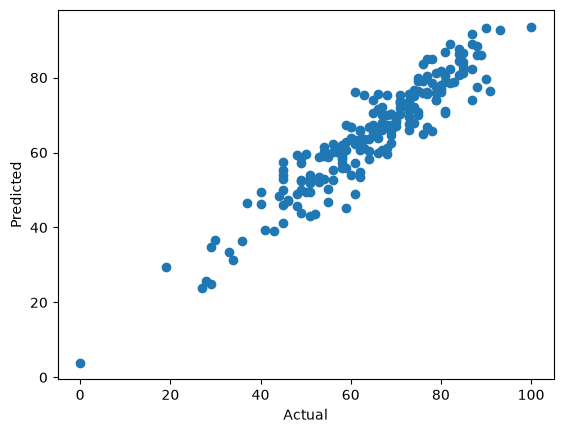

In [13]:
plt.scatter(y_test, y_pred)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.show()

### Difference between actual and predicted values

In [14]:
pred_df = pd.DataFrame({'Actual value': y_test, 'Predicted value':y_pred, 'Difference':y_test-y_pred})
pred_df

,Actual value,Predicted value,Difference
521,91,76.398705,14.601295
737,53,58.842469,-5.842469
740,80,76.992129,3.007871
660,74,76.805898,-2.805898
411,84,87.615387,-3.615387
...,...,...,...
408,52,43.492293,8.507707
332,62,62.170763,-0.170763
208,74,67.910325,6.089675
613,65,67.061504,-2.061504
